Student: Mihhail Korasteljov

Subject: Energy Data Science ITS8080, autumn semester 2026

Solution for Assignement 6. Feature engineering 


**6. Feature engineering [7pt]**

Tips: Work with demand and weather-related data. You may use simple ranking analysis.

6.1. Provide a description of the data, including statistics and 2–3 visuals to gain insights.





In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Use the dataset from your project
df = pd.read_csv("266050_training.csv")

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.set_index("timestamp").sort_index()

# Select demand and weather variables
cols = [
    "Demand",
    "Temperature",
    "Cloud_cover (%)",
    "Wind_speed_10m (km/h)"
]

# Descriptive statistics
stats = df[cols].describe().T
stats["missing"] = df[cols].isna().sum()
stats["skewness"] = df[cols].skew()

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,missing,skewness
Demand,8759.0,0.531,0.376,0.0,0.283,0.377,0.656,4.137,0,2.492
Temperature,8759.0,7.515,8.312,-18.3,2.000,6.800,14.000,28.900,0,-0.209
Cloud_cover (%),8759.0,68.705,36.274,0.0,39.000,88.000,100.000,100.000,0,-0.778
Wind_speed_10m (km/h),8759.0,15.991,7.451,0.4,10.400,15.000,21.100,51.100,0,0.505


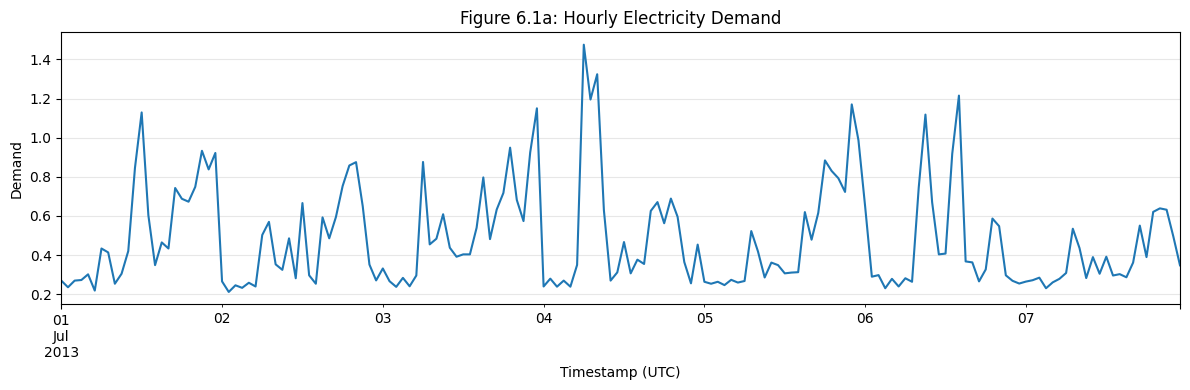

In [4]:
# Electrisity demand for 7 days (7*24=168h)
# Select the first seven days
week = df["Demand"].iloc[:168]

ax = week.plot(
    figsize=(12, 4),
    title="Figure 6.1a: Hourly Electricity Demand"
)

ax.set_xlabel("Timestamp (UTC)")
ax.set_ylabel("Demand")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

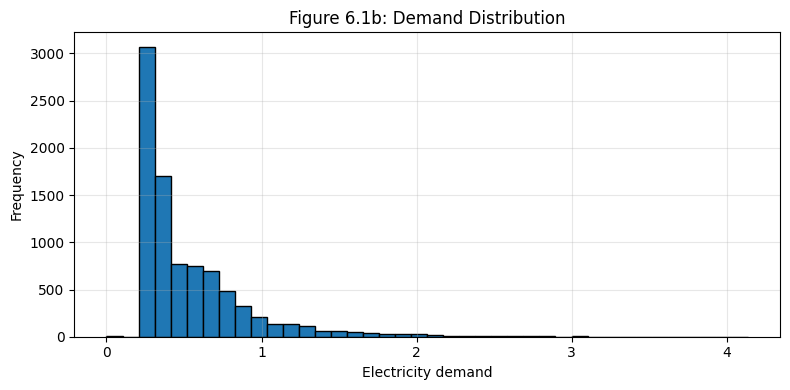

In [5]:
#Demand distribution histogram
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    df["Demand"].dropna(),
    bins=40,
    edgecolor="black"
)

ax.set_title("Figure 6.1b: Demand Distribution")
ax.set_xlabel("Electricity demand")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

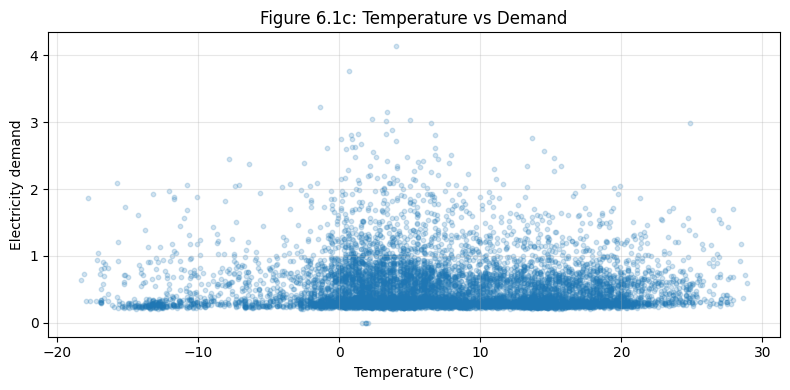

In [6]:
#temperature vs demand
fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    df["Temperature"],
    df["Demand"],
    alpha=0.2,
    s=10
)

ax.set_title("Figure 6.1c: Temperature vs Demand")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Electricity demand")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

RESULTS 6.1: 

The dataset contains 8,759 hourly observations of electricity demand and weather conditions.

Average electricity demand is 0.531, with a maximum of 4.137. Average temperature is 7.52°C, ranging from -18.3°C to 28.9°C. The selected variables have no missing values.

Figure 6.1a shows how electricity demand changes over time. Figure 6.1b shows a right-skewed demand distribution, with occasional high values. Figure 6.1c shows a weak linear relationship between temperature and demand.


**6.2. Analyse distributions.**

(a) Are the data normally distributed?



Skewness:
Demand                   2.492
Temperature             -0.209
Cloud_cover (%)         -0.778
Wind_speed_10m (km/h)    0.505
dtype: float64


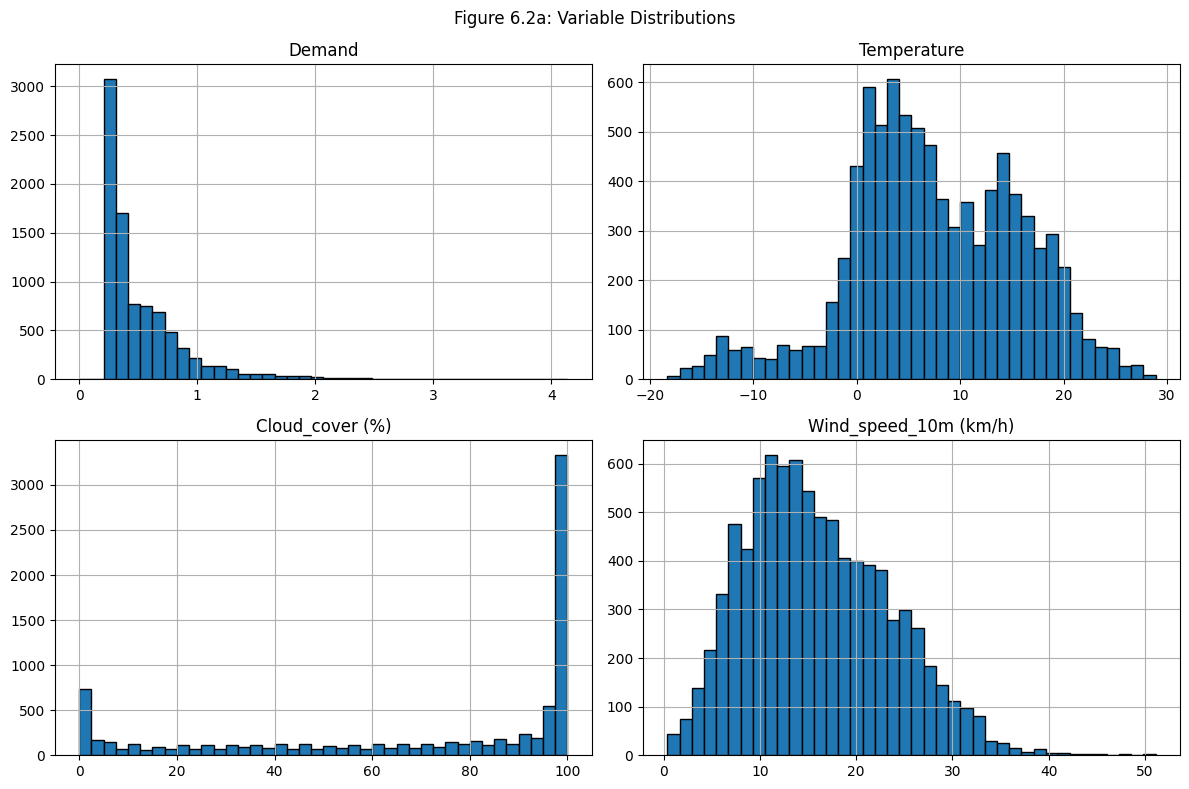

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cols = [
    "Demand",
    "Temperature",
    "Cloud_cover (%)",
    "Wind_speed_10m (km/h)"
]

# Calculate skewness
print("Skewness:")
print(df[cols].skew().round(3))

# Plot histograms
df[cols].hist(
    bins=40,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Figure 6.2a: Variable Distributions")
plt.tight_layout()
plt.show()

(b) Are any transformations needed? Apply the latter if relevant.

,Original,Log1p,Square root
Skewness,2.492,1.585,1.477


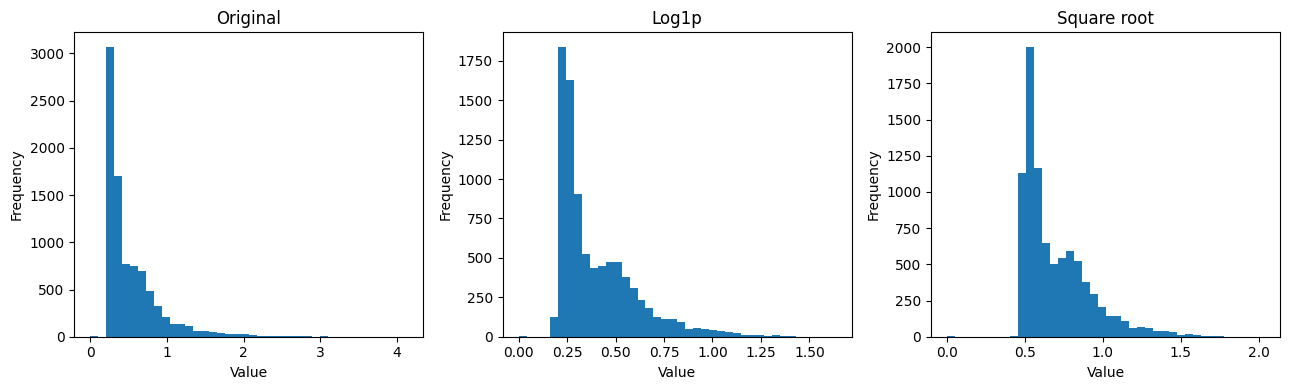

In [8]:
# Apply transformations to Demand
df["Demand_log"] = np.log1p(df["Demand"])
df["Demand_sqrt"] = np.sqrt(df["Demand"])

# Compare skewness
comparison = pd.DataFrame({
    "Original": [df["Demand"].skew()],
    "Log1p": [df["Demand_log"].skew()],
    "Square root": [df["Demand_sqrt"].skew()]
}, index=["Skewness"])

display(comparison.round(3))

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, title in zip(
    axes,
    ["Demand", "Demand_log", "Demand_sqrt"],
    ["Original", "Log1p", "Square root"]
):
    ax.hist(df[col].dropna(), bins=40)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

RESULTS for 6.2: 

Electricity demand is not normally distributed (skewness=0, normal Gaussian). Its skewness is 2.49, indicating a long right tail with occasional high values.

I applied a log1p transformation (as in practical_07) to reduce skewness. This transformation handles zero values and reduces the influence of high demand peaks.

6.3. Create at least one lag feature, one calendar/time-related feature, and one weather
based feature. For the lag feature, justify the chosen lag.

In [12]:
import numpy as np
import pandas as pd

# Work on a copy of the original data
features_df = df.copy().sort_index()

# 1. Lag features
features_df["demand_lag1"] = features_df["Demand"].shift(1)   #Electricity demand one hour earlier
features_df["demand_lag24"] = features_df["Demand"].shift(24)  #demand 24h earlier

# 2. Calendar features
features_df["hour"] = features_df.index.hour   #Hour of the day (0–23)
features_df["weekday"] = features_df.index.dayofweek   #Day of the week (0-6)
features_df["is_weekend"] = (
    features_df.index.dayofweek >= 5
).astype(int)


# 3. Weather-based feature
# Heating degree relative to 18°C
features_df["heating_degree"] = np.maximum(             #Temperature one hour earlier
    18 - features_df["Temperature"].shift(1), 0
)


# Display engineered features
selected = [
    "Demand",
    "demand_lag1",
    "demand_lag24",
    "hour",
    "weekday",
    "is_weekend",
    "heating_degree",
]

display(features_df[selected].iloc[24:34].round(3))

,Demand,demand_lag1,demand_lag24,hour,weekday,is_weekend,heating_degree
timestamp,,,,,,,
2013-07-02 00:00:00+00:00,0.266,0.922,0.270,0,1,0,5.3
2013-07-02 01:00:00+00:00,0.212,0.266,0.236,1,1,0,5.7
2013-07-02 02:00:00+00:00,0.246,0.212,0.270,2,1,0,5.9
2013-07-02 03:00:00+00:00,0.233,0.246,0.273,3,1,0,6.3
2013-07-02 04:00:00+00:00,0.259,0.233,0.302,4,1,0,6.6
2013-07-02 05:00:00+00:00,0.240,0.259,0.219,5,1,0,6.1
2013-07-02 06:00:00+00:00,0.503,0.240,0.434,6,1,0,5.0
2013-07-02 07:00:00+00:00,0.570,0.503,0.414,7,1,0,3.5
2013-07-02 08:00:00+00:00,0.353,0.570,0.254,8,1,0,2.1


RESULTS for 6.3:I created lag, calendar, and weather-based features to support electricity demand forecasting.
Lag-1 uses demand from the previous hour, while lag-24 captures daily consumption patterns. Calendar features describe the hour, weekday, and weekend. I also created a heating-degree feature using the previous hour's temperature and a base temperature of 18°C.


6.4. For every feature you create, state the exact time at which its value becomes known.
Mark any feature that would not be available at prediction time with a 0h lead time
and remove it from the modelling set. Explain what would have gone wrong had you
kept it.

In [15]:


feature_availability = pd.DataFrame({
    "Feature": [
        "demand_lag1",
        "demand_lag24",
        "hour",
        "weekday",
        "is_weekend",
        "heating_degree",
        "Demand"
    ],
    "Available_at_prediction": [
        True, True, True, True, True,
        True, False
    ]
})

display(feature_availability)

# Select only available predictors
safe_features = feature_availability.loc[
    feature_availability["Available_at_prediction"],
    "Feature"
].tolist()

# Create modelling dataset
model_df = features_df[
    safe_features + ["Demand"]
].dropna()

X = model_df[safe_features]
y = model_df["Demand"]

print("Safe features:", safe_features)
print("Modelling dataset shape:", X.shape)

,Feature,Available_at_prediction
0,demand_lag1,True
1,demand_lag24,True
2,hour,True
3,weekday,True
4,is_weekend,True
5,heating_degree,True
6,Demand,False


Safe features: ['demand_lag1', 'demand_lag24', 'hour', 'weekday', 'is_weekend', 'heating_degree']
Modelling dataset shape: (8735, 6)


ANSWER for 6.4: 

I checked six engineered features for their availability at prediction time. Lag-1, lag-24, and heating-degree features use previous measurements, while hour, weekday, and weekend features are known in advance.

All six features are available for one-step-ahead prediction, assuming previous measurements have arrived. Current Demand was excluded because it is the target variable and would cause data leakage.


6.5. Rank features by relevance.
(a) Explain the rationale behind your ranking. Why do the top-ranked features make
sense in the context of the considered application?
(b) If the engineered feature is poorly ranked, what could be the reason?

,Correlation,Abs_correlation
demand_lag1,0.540,0.540
hour,0.282,0.282
demand_lag24,0.245,0.245
heating_degree,0.055,0.055
weekday,0.013,0.013
is_weekend,-0.001,0.001


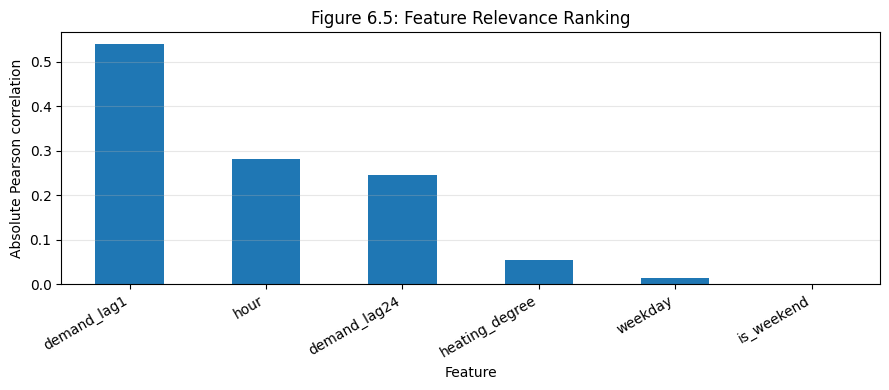

In [16]:


import pandas as pd
import matplotlib.pyplot as plt

# Calculate Pearson correlation with Demand
ranking = X.corrwith(y).to_frame(
    name="Correlation"
)

# Rank by absolute correlation
ranking["Abs_correlation"] = ranking["Correlation"].abs()

ranking = ranking.sort_values(
    "Abs_correlation", ascending=False
)

display(ranking.round(3))

# Plot ranking
ax = ranking["Abs_correlation"].plot(
    kind="bar",
    figsize=(9, 4),
    title="Figure 6.5: Feature Relevance Ranking"
)

ax.set_xlabel("Feature")
ax.set_ylabel("Absolute Pearson correlation")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

ANSWER for 6.5: 

I ranked six features using absolute Pearson correlation with electricity demand.

The most relevant feature is `demand_lag1` (0.54), followed by `hour` (0.28) and `demand_lag24` (0.24). This makes sense because electricity consumption depends on recent demand and daily household routines.

Weather and weekday features have weaker correlations. Heating degree may have low relevance because household electricity demand is not necessarily dominated by electric heating. Weekday and weekend features may also have nonlinear relationships that Pearson correlation does not capture.